# Step 3: Label Distribution Smoothing (LDS) Weights

**Objective:** Derive per-sample loss weights that counteract the strong non-uniformity of the target distribution, and write them into the catalog for static deployment.

**The imbalance.** After the cuts of Steps 1-2 the target distribution is dominated by the G-dwarf peak near 5900 K, while the 7000-9000 K tail is sparse. At 100 K resolution the raw density ratio between the most and least populated bins is of order a few hundred to one. Left uncorrected, the optimiser sees the hot tail as a rounding error.

**Why smoothing.** Weighting by the raw inverse frequency makes the weight of a bin depend on its own count alone, so a bin that happens to hold 40 stars and its neighbour that holds 90 receive weights differing by more than a factor of two, despite describing the same physical regime. Stellar spectra vary continuously with temperature, so the effective density should too. A Gaussian kernel over the binned histogram enforces that continuity before the inverse is taken.

**Weights are applied to training only.** Validation and test samples keep a weight of exactly 1.0, so that the reported RMSE is a physical error rather than a re-weighted one. This matters especially here, because the degradation measured under perturbation must be comparable across temperature regimes.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.size': 12,
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'stix',
})

catalog_path = 'data/sdss_final_catalog.csv'
meta_path = 'data/preprocessing_meta.json'

# ==========================================
# CONFIGURATION
# ==========================================
BIN_SIZE = 100          # K
SIGMA = 2.0             # Gaussian kernel width, in bins (= 200 K)
ALPHA = 0.5             # weight exponent: w ~ 1 / p'(y)^ALPHA
DENSITY_FLOOR = 1.0     # minimum effective count per bin, in units of stars

# ALPHA = 1.0 reproduces the textbook inverse-density weighting; ALPHA = 0.5
# is the square-root variant. The choice matters: see the diagnostic below,
# which reports the resulting dynamic range for both.
#
# DENSITY_FLOOR caps the weight a bin can receive. Expressed in stars rather
# than as an arbitrary epsilon, it states plainly that a bin whose smoothed
# occupancy is below one star is treated as holding one star.

print("Loading final catalog...")
df = pd.read_csv(catalog_path)

with open(meta_path) as f:
    meta = json.load(f)
print(f"  {len(df):,} spectra, Teff {df['teff'].min():.1f} - {df['teff'].max():.1f} K")
print(f"  splits: " + ", ".join(f"{k}={v:,}" for k, v in df['dataset_split'].value_counts().items()))

train_mask = (df['dataset_split'] == 'train').values
train_teff = df.loc[train_mask, 'teff'].values
print(f"\nWeights are derived from the {train_mask.sum():,} training spectra only.")

Loading final catalog...
  188,972 spectra, Teff 3500.0 - 8999.3 K
  splits: train=151,176, val=18,898, test=18,898

Weights are derived from the 151,176 training spectra only.


## 3.1 Smoothed density and weight computation

Four implementation details determine whether the result behaves as intended.

**The histogram is cast to float before smoothing.** `gaussian_filter1d` preserves the dtype of its input, so passing the integer histogram directly rounds the smoothed density to whole numbers. The error reaches several per cent in exactly the sparse bins the procedure exists to protect.

**The binning range follows the data.** Bins are laid out over the observed extent of the training labels rather than over a fixed interval, so that no empty bins are created beyond the edges of the sample.

**The floor is expressed in stars.** A smoothed occupancy below one star is treated as one star, which places a definite ceiling on the weight any bin can receive and makes that ceiling interpretable.

**Normalisation is applied after mapping to samples.** This is the substantive correction relative to a bin-level normalisation. Dividing the *bin* array by its own mean gives equal say to a bin holding 15,000 stars and one holding 40; since the sparse bins carry the large weights, the mean is pulled upward and almost every actual sample ends up with a weight far below one. The effective learning rate is then silently scaled down by whatever that factor happens to be. Normalising the *per-sample* array instead guarantees a mean weight of exactly 1.0 over the training set, which is what leaves the optimiser's step size intact.

In [2]:
# ==========================================
# 1. SMOOTHED DENSITY
# ==========================================
lo = np.floor(train_teff.min() / BIN_SIZE) * BIN_SIZE
hi = np.ceil(train_teff.max() / BIN_SIZE) * BIN_SIZE
bins = np.arange(lo, hi + BIN_SIZE, BIN_SIZE)
bin_centers = 0.5 * (bins[1:] + bins[:-1])

hist, _ = np.histogram(train_teff, bins=bins)

# cast to float: gaussian_filter1d preserves dtype and would otherwise round
smoothed = gaussian_filter1d(hist.astype(np.float64), sigma=SIGMA)
smoothed_floored = np.maximum(smoothed, DENSITY_FLOOR)
n_floored = int((smoothed < DENSITY_FLOOR).sum())

print(f"Binning: {len(bins)-1} bins of {BIN_SIZE} K over "
      f"[{lo:.0f}, {hi:.0f}] K")
print(f"  raw density     : min {hist.min():,}  max {hist.max():,}  "
      f"ratio {hist.max()/max(hist.min(),1):.0f}:1")
print(f"  smoothed density: min {smoothed.min():.1f}  max {smoothed.max():.1f}  "
      f"ratio {smoothed.max()/smoothed.min():.1f}:1")
print(f"  bins at the density floor: {n_floored}")

# ==========================================
# 2. PER-BIN WEIGHTS, THEN PER-SAMPLE NORMALISATION
# ==========================================
w_bin = 1.0 / np.power(smoothed_floored, ALPHA)

bin_index = np.clip(np.digitize(df['teff'].values, bins) - 1, 0, len(w_bin) - 1)
w_sample_train = w_bin[bin_index[train_mask]]

# normalise over SAMPLES so that the mean training weight is exactly 1.0
norm_factor = w_sample_train.mean()
w_sample_train = w_sample_train / norm_factor
w_bin_plot = w_bin / norm_factor          # same scaling, for the figure

print(f"\nWeights with ALPHA = {ALPHA}")
print(f"  per-sample mean   : {w_sample_train.mean():.6f}  (must be 1.000000)")
print(f"  per-sample median : {np.median(w_sample_train):.4f}")
print(f"  range             : {w_sample_train.min():.3f} - "
      f"{w_sample_train.max():.2f}  ({w_sample_train.max()/w_sample_train.min():.1f}:1)")

# what the alternative exponent would have given
for a in [0.5, 1.0]:
    wb = 1.0 / np.power(smoothed_floored, a)
    ws = wb[bin_index[train_mask]]
    ws = ws / ws.mean()
    tag = "  <- selected" if a == ALPHA else ""
    print(f"    ALPHA={a}: dynamic range {ws.max()/ws.min():6.1f}:1, "
          f"median {np.median(ws):.4f}{tag}")

Binning: 55 bins of 100 K over [3500, 9000] K
  raw density     : min 31  max 12,068  ratio 389:1
  smoothed density: min 61.5  max 8953.3  ratio 145.6:1
  bins at the density floor: 0

Weights with ALPHA = 0.5
  per-sample mean   : 1.000000  (must be 1.000000)
  per-sample median : 0.9300
  range             : 0.635 - 7.66  (12.1:1)
    ALPHA=0.5: dynamic range   12.1:1, median 0.9300  <- selected
    ALPHA=1.0: dynamic range  145.6:1, median 0.6919


## 3.2 Writing the weights into the catalog

Validation and test rows are set to exactly 1.0. Their weights are never
consumed during training, but the column must be well-defined because the data
loader reads it for every partition.


In [3]:
# ==========================================
# 3. WRITE TO CATALOG
# ==========================================
df['lds_weight'] = 1.0
df.loc[train_mask, 'lds_weight'] = w_sample_train

# --- verification ------------------------------------------------------------
chk_train = df.loc[train_mask, 'lds_weight']
chk_other = df.loc[~train_mask, 'lds_weight']
assert np.isclose(chk_train.mean(), 1.0), "training weights are not mean-normalised"
assert (chk_other == 1.0).all(), "non-training rows must carry weight 1.0"
assert df['lds_weight'].notna().all(), "NaN in the weight column"
assert (df['lds_weight'] > 0).all(), "non-positive weight"

df.to_csv(catalog_path, index=False)
print(f"Catalog updated: {catalog_path}")
print(f"  train weights : mean {chk_train.mean():.6f}, "
      f"min {chk_train.min():.4f}, max {chk_train.max():.4f}")
print(f"  val/test      : all equal to 1.0 ({len(chk_other):,} rows)")

# --- weight by temperature regime --------------------------------------------
regime = pd.cut(df.loc[train_mask, 'teff'],
                bins=[3500, 4000, 4500, 5000, 5500, 6000, 6500, 7000, 8000, 9000])
tab = df.loc[train_mask].groupby(regime, observed=True).agg(
    n=('lds_weight', 'size'),
    weight_median=('lds_weight', 'median'),
    weight_max=('lds_weight', 'max'),
)
tab['share_of_samples_%'] = (100 * tab['n'] / tab['n'].sum()).round(2)
tab['share_of_gradient_%'] = (
    100 * df.loc[train_mask].groupby(regime, observed=True)['lds_weight'].sum()
    / df.loc[train_mask, 'lds_weight'].sum()).round(2)
tab['leverage'] = (tab['share_of_gradient_%'] / tab['share_of_samples_%']).round(2)
print("\nGradient share by temperature regime:")
display(tab.round(4))

# --- persist the configuration -----------------------------------------------
lds_meta = {
    'bin_size_K':       BIN_SIZE,
    'bin_range_K':      [float(lo), float(hi)],
    'n_bins':           int(len(bins) - 1),
    'sigma_bins':       SIGMA,
    'sigma_K':          SIGMA * BIN_SIZE,
    'alpha':            ALPHA,
    'density_floor':    DENSITY_FLOOR,
    'n_bins_floored':   n_floored,
    'normalisation':    'per-sample mean = 1.0 over the training partition',
    'fitted_on':        'train',
    'val_test_weight':  1.0,
    'weight_min':       float(w_sample_train.min()),
    'weight_max':       float(w_sample_train.max()),
    'weight_median':    float(np.median(w_sample_train)),
    'dynamic_range':    float(w_sample_train.max() / w_sample_train.min()),
}
with open('data/lds_meta.json', 'w') as f:
    json.dump(lds_meta, f, indent=2)
print("\nConfiguration written to data/lds_meta.json")

Catalog updated: data/sdss_final_catalog.csv
  train weights : mean 1.000000, min 0.6349, max 7.6607
  val/test      : all equal to 1.0 (37,796 rows)

Gradient share by temperature regime:


,n,weight_median,weight_max,share_of_samples_%,share_of_gradient_%,leverage
teff,,,,,,
"(3500, 4000]",10299,1.2680,1.4137,6.81,8.91,1.31
"(4000, 4500]",10942,1.1769,1.3996,7.24,8.91,1.23
"(4500, 5000]",20138,0.9577,1.0399,13.32,12.89,0.97
"(5000, 5500]",19602,0.9317,0.9379,12.97,11.90,0.92
"(5500, 6000]",43596,0.6366,0.7873,28.84,19.26,0.67
"(6000, 6500]",26156,0.7266,1.0611,17.30,13.49,0.78
"(6500, 7000]",9852,1.3339,1.3810,6.52,8.55,1.31
"(7000, 8000]",8607,1.7302,2.7917,5.69,11.03,1.94
"(8000, 9000]",1984,3.4027,7.6607,1.31,5.06,3.86



Configuration written to data/lds_meta.json


## 3.3 Verification figure

The raw inverse density and the smoothed variant, on the same normalisation, so the two curves are directly comparable. The horizontal line at 1.0 marks the mean weight over the training set: the smoothed curve crosses it where a sample is neither up- nor down-weighted.

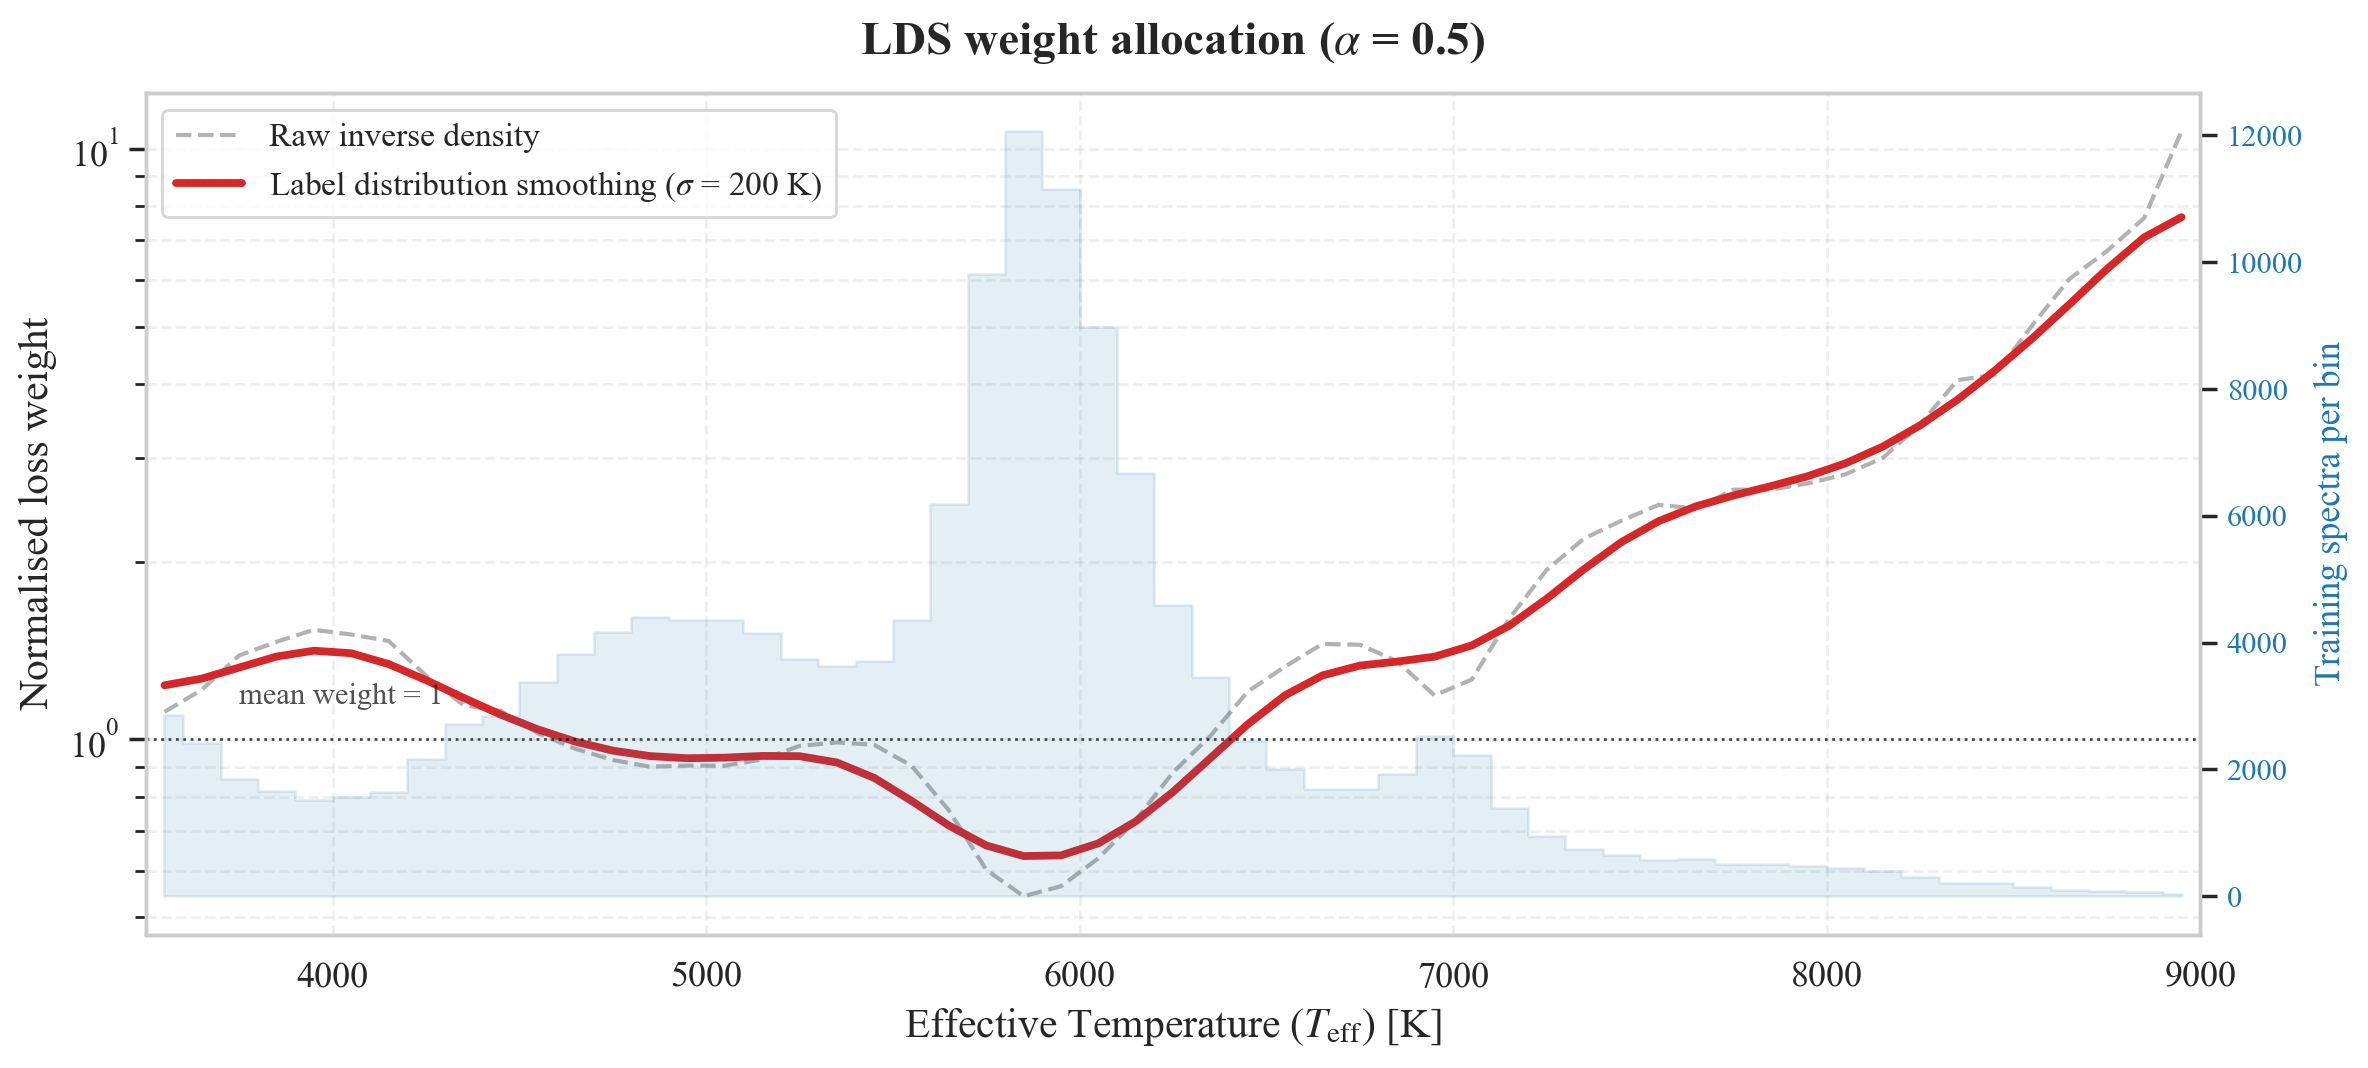

In [4]:
raw_w = 1.0 / np.power(np.maximum(hist.astype(np.float64), DENSITY_FLOOR), ALPHA)
raw_w_sample = raw_w[bin_index[train_mask]]
raw_w_plot = raw_w / raw_w_sample.mean()

fig, ax = plt.subplots(figsize=(12, 5.5), dpi=200)

ax.plot(bin_centers, raw_w_plot, color='gray', alpha=0.6, linestyle='--', linewidth=1.5, label='Raw inverse density')
ax.plot(bin_centers, w_bin_plot, color='#d62728', linewidth=2.8, label=rf'Label distribution smoothing ($\sigma$ = {SIGMA * BIN_SIZE:.0f} K)')
ax.axhline(1.0, color='black', linewidth=1.0, linestyle=':', alpha=0.7)
ax.text(bin_centers[2], 1.15, 'mean weight = 1', fontsize=11, alpha=0.8)

ax.set_yscale('log')
ax.set_xlabel(r"Effective Temperature ($T_{\mathrm{eff}}$) [K]", fontsize=15)
ax.set_ylabel("Normalised loss weight", fontsize=15)
ax.set_title(rf"LDS weight allocation ($\alpha$ = {ALPHA})", fontsize=17, fontweight='bold', pad=14)
ax.set_xlim(lo, hi)
ax.grid(True, which="both", ls="--", alpha=0.3)
ax.legend(fontsize=12, loc='upper left')
ax.tick_params(labelsize=13)

# density on a twin axis for context
ax2 = ax.twinx()
ax2.fill_between(bin_centers, hist, color='#1f77b4', alpha=0.12, step='mid')
ax2.set_ylabel("Training spectra per bin", fontsize=13, color='#1f77b4')
ax2.tick_params(axis='y', labelcolor='#1f77b4', labelsize=11)
ax2.grid(False)

plt.tight_layout()
plt.show()